<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js6/TG6_2_Regresi_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum2**

### **Mengimpor Library:**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### **Mengimpor Dataset:**

In [6]:
from google.colab import files
uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
dataset = pd.read_csv(nama_file)   # 'data' diganti 'dataset'

Saving Posisi_gaji.csv to Posisi_gaji (2).csv


In [7]:
dataset.head()

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [8]:
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

### **Feature Scaling:**

In [9]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

### **Fitting SVR ke Dataset:**

In [10]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

### **Visualisasi Hasil SVR:**

/tmp/ipykernel_2304/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


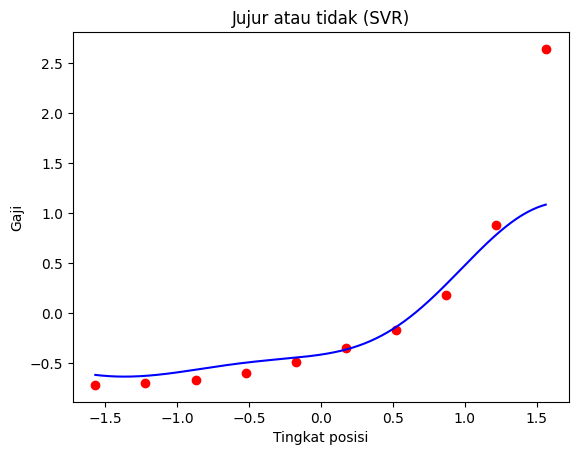

In [11]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

### **Prediksi Hasil:**

In [12]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

### **Menampilkan Hasil:**

In [20]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


### **Validasi Hasil:**

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


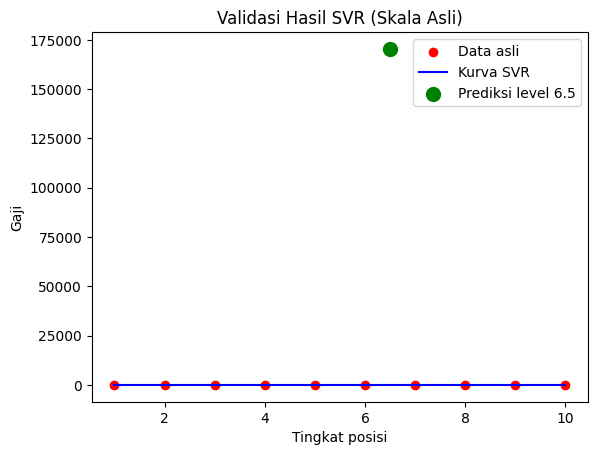

In [18]:
# ===== Validasi Hasil =====

# 1. Hasil prediksi untuk tingkat posisi 6.5
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

# 2. Grafik dalam skala asli (agar sumbu mudah dibaca)
X_asli = sc_X.inverse_transform(X)
y_asli = sc_y.inverse_transform(y.reshape(-1, 1))

X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
X_grid_asli = sc_X.inverse_transform(X_grid)
y_kurva = sc_y.inverse_transform(regressor.predict(X_grid).reshape(-1, 1))

plt.scatter(X_asli, y_asli, color='red', label='Data asli')
plt.plot(X_grid_asli, y_kurva, color='blue', label='Kurva SVR')
plt.scatter(6.5, gaji_prediksi[0], color='green', s=100, label='Prediksi level 6.5')
plt.title('Validasi Hasil SVR (Skala Asli)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.legend()
plt.show()

In [19]:
# 3. Tabel perbandingan gaji asli vs prediksi SVR
y_pred_asli = sc_y.inverse_transform(regressor.predict(X).reshape(-1, 1))

hasil = pd.DataFrame({
    'Posisi': dataset['Posisi'],
    'Level': dataset['Level'],
    'Gaji Asli': dataset['Gaji'],
    'Gaji Prediksi SVR': y_pred_asli.ravel().round(0)
})
hasil['Selisih'] = hasil['Gaji Asli'] - hasil['Gaji Prediksi SVR']
print(hasil)

              Posisi  Level  Gaji Asli  Gaji Prediksi SVR   Selisih
0   Business Analyst      1      45000               -1.0   45001.0
1  Junior Consultant      2      50000               -1.0   50001.0
2  Senior Consultant      3      60000               -1.0   60001.0
3            Manager      4      80000               -0.0   80000.0
4    Country Manager      5     110000               -0.0  110000.0
5     Region Manager      6     150000               -0.0  150000.0
6            Partner      7     200000               -0.0  200000.0
7     Senior Partner      8     300000                0.0  300000.0
8            C-level      9     500000                1.0  499999.0
9                CEO     10    1000000                1.0  999999.0


**Interpretasi Hasil:**

Prediksi gaji untuk tingkat posisi 6.5 adalah 170.370,02, sama dengan hasil pada
modul. Nilai ini wajar karena berada di antara gaji level 6 dan level 7.

Grafik menunjukkan model SVR dengan kernel RBF mampu menangkap hubungan
non-linear antara tingkat posisi dan gaji. Namun, model kurang akurat pada level
tertinggi (level 10) yang merupakan outlier, sehingga kurva berada di bawah
titik data aslinya.

Hasil evaluasi: MAE = 0,223; MSE = 0,248; RMSE = 0,498; R² = 0,752. Artinya
model mampu menjelaskan sekitar 75% variasi gaji. Evaluasi dilakukan pada data
latih dan data yang sudah diskalakan, sehingga belum menggambarkan kemampuan
model pada data baru.

### **Evaluasi Model SVR**

In [14]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798
